In [10]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [11]:
import zipfile
import os

zip_path = "/content/drive/MyDrive/BCICIV_1_mat.zip" # Change this to your actual zip file path
extract_path = "/content/eeg_data"

# Unzip the file
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("✅ Unzipping complete. Files extracted to:", extract_path)

✅ Unzipping complete. Files extracted to: /content/eeg_data


In [12]:
import os

for root, dirs, files in os.walk(extract_path):
    for file in files:
        print(os.path.join(root, file))

/content/eeg_data/BCICIV_eval_ds1a.mat
/content/eeg_data/BCICIV_eval_ds1e.mat
/content/eeg_data/BCICIV_eval_ds1b.mat
/content/eeg_data/BCICIV_calib_ds1a.mat
/content/eeg_data/BCICIV_calib_ds1c.mat
/content/eeg_data/BCICIV_calib_ds1b.mat
/content/eeg_data/BCICIV_eval_ds1g.mat
/content/eeg_data/BCICIV_calib_ds1g.mat
/content/eeg_data/BCICIV_calib_ds1e.mat
/content/eeg_data/BCICIV_calib_ds1f.mat
/content/eeg_data/BCICIV_eval_ds1d.mat
/content/eeg_data/BCICIV_eval_ds1c.mat
/content/eeg_data/BCICIV_eval_ds1f.mat
/content/eeg_data/BCICIV_calib_ds1d.mat


In [13]:
!pip install mne scipy numpy pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.4/7.4 MB 39.7 MB/s eta 0:00:00


In [14]:
import numpy as np
import pandas as pd
import scipy.io
from scipy.signal import butter, lfilter
from mne.decoding import UnsupervisedSpatialFilter
from sklearn.decomposition import FastICA
from scipy.signal import welch
import matplotlib.pyplot as plt

In [15]:
# Path to your .mat file
eeg_file_path = "/content/eeg_data/BCICIV_calib_ds1g.mat"

# Load the .mat file
mat = scipy.io.loadmat(eeg_file_path)




In [16]:
# See keys in the file
print("Available keys:", mat.keys())

Available keys: dict_keys(['__header__', '__version__', '__globals__', 'mrk', 'cnt', 'nfo'])


In [17]:
eeg_data = mat['cnt']  # This might vary depending on dataset

print("EEG shape:", eeg_data.shape)
print("EEG dtype:", eeg_data.dtype)

EEG shape: (190602, 59)
EEG dtype: int16


In [18]:
nfo = mat['nfo']

print(nfo.dtype)

[('fs', 'O'), ('classes', 'O'), ('clab', 'O'), ('xpos', 'O'), ('ypos', 'O')]


In [19]:
sfreq = mat['nfo']['fs'][0][0][0][0]
EEGdata   = mat['cnt'].T
nchannels, nsamples = EEGdata.shape

chan_names = [s[0] for s in mat['nfo']['clab'][0][0][0]]

event_onsets  = mat['mrk'][0][0][0]
event_codes   = mat['mrk'][0][0][1]

labels = np.zeros((1, nsamples), int)
labels[0, event_onsets] = event_codes

cl_lab = [s[0] for s in mat['nfo']['classes'][0][0][0]]
cl1    = cl_lab[0]
cl2    = cl_lab[1]

# digitized electrode positions
xpos = mat['nfo']['xpos']
ypos = mat['nfo']['ypos']

nclasses = len(cl_lab)
nevents = len(event_onsets)

# Print some information
print('Shape of EEG:', EEGdata.shape)
print('Sample rate:', sfreq)
print('Number of channels:', nchannels)
print('Channel names:', chan_names)
print('Number of events:', len(event_onsets))
print('Event codes:', np.unique(event_codes))
print('Class labels:', cl_lab)
print('Number of classes:', nclasses)

Shape of EEG: (59, 190602)
Sample rate: 100
Number of channels: 59
Channel names: [np.str_('AF3'), np.str_('AF4'), np.str_('F5'), np.str_('F3'), np.str_('F1'), np.str_('Fz'), np.str_('F2'), np.str_('F4'), np.str_('F6'), np.str_('FC5'), np.str_('FC3'), np.str_('FC1'), np.str_('FCz'), np.str_('FC2'), np.str_('FC4'), np.str_('FC6'), np.str_('CFC7'), np.str_('CFC5'), np.str_('CFC3'), np.str_('CFC1'), np.str_('CFC2'), np.str_('CFC4'), np.str_('CFC6'), np.str_('CFC8'), np.str_('T7'), np.str_('C5'), np.str_('C3'), np.str_('C1'), np.str_('Cz'), np.str_('C2'), np.str_('C4'), np.str_('C6'), np.str_('T8'), np.str_('CCP7'), np.str_('CCP5'), np.str_('CCP3'), np.str_('CCP1'), np.str_('CCP2'), np.str_('CCP4'), np.str_('CCP6'), np.str_('CCP8'), np.str_('CP5'), np.str_('CP3'), np.str_('CP1'), np.str_('CPz'), np.str_('CP2'), np.str_('CP4'), np.str_('CP6'), np.str_('P5'), np.str_('P3'), np.str_('P1'), np.str_('Pz'), np.str_('P2'), np.str_('P4'), np.str_('P6'), np.str_('PO1'), np.str_('PO2'), np.str_('O1'

In [20]:
# Extract data and metadata
cnt = mat['cnt']               # EEG data (samples × channels)
nfo = mat['nfo']               # Metadata
fs = int(nfo['fs'][0, 0][0, 0])  # Sampling frequency (100 Hz)
channel_labels = [str(label[0]) for label in nfo['clab'][0, 0][0]]

print("Shape:", cnt.shape)
print("Sampling Rate:", fs)
print("Channels:", channel_labels[:])

Shape: (190602, 59)
Sampling Rate: 100
Channels: ['AF3', 'AF4', 'F5', 'F3', 'F1', 'Fz', 'F2', 'F4', 'F6', 'FC5', 'FC3', 'FC1', 'FCz', 'FC2', 'FC4', 'FC6', 'CFC7', 'CFC5', 'CFC3', 'CFC1', 'CFC2', 'CFC4', 'CFC6', 'CFC8', 'T7', 'C5', 'C3', 'C1', 'Cz', 'C2', 'C4', 'C6', 'T8', 'CCP7', 'CCP5', 'CCP3', 'CCP1', 'CCP2', 'CCP4', 'CCP6', 'CCP8', 'CP5', 'CP3', 'CP1', 'CPz', 'CP2', 'CP4', 'CP6', 'P5', 'P3', 'P1', 'Pz', 'P2', 'P4', 'P6', 'PO1', 'PO2', 'O1', 'O2']


In [21]:
def plot_eeg(data, title="EEG Signals", sr=100):
    time = np.arange(data.shape[0]) / sr
    channels = min(data.shape[1], 8)
    plt.figure(figsize=(15, 10))
    for i in range(channels):
        plt.subplot(channels, 1, i+1)
        plt.plot(time, data[:, i])
        plt.title(f"{title} - Channel {i+1}")
        plt.ylabel("Amplitude")
    plt.xlabel("Time (s)")
    plt.tight_layout()
    plt.show()

plot_eeg(eeg_data, title="Raw EEG Signal", sr=sampling_rate)

NameError: name 'sampling_rate' is not defined

In [22]:
sampling_rate = 100
time = np.arange(eeg_signal.shape[0]) / sampling_rate

plt.figure(figsize=(15, 10))
for i in range(channels_to_plot):
    plt.subplot(channels_to_plot, 1, i+1)
    plt.plot(time, eeg_signal[:, i])
    plt.title(f"Channel {i+1}")
    plt.ylabel("Amplitude")
    plt.xlabel("Time (s)")
plt.tight_layout()
plt.show()


NameError: name 'eeg_signal' is not defined

In [23]:
selected_channels = ['AF3', 'F5', 'F3', 'FC5', 'T7', 'P5', 'O1', 'O2',
                     'P6', 'T8', 'FC6', 'F4', 'F6', 'AF4']

# Get their indices from the channel labels
selected_indices = [channel_labels.index(ch) for ch in selected_channels]

# Extract only those channels
eeg_data = cnt[:, selected_indices].astype(np.float32)

In [24]:
from scipy.signal import butter, filtfilt, welch
from numpy.fft import fft, ifft
from sklearn.decomposition import FastICA

In [25]:
def bandpass_filter(data, lowcut, highcut, fs, order=5):
    nyquist = 0.5 * fs
    b, a = butter(order, [lowcut / nyquist, highcut / nyquist], btype='band')
    return filtfilt(b, a, data, axis=0)

filtered_eeg = bandpass_filter(eeg_data, 4, 40, fs)

In [26]:
ica = FastICA(n_components=filtered_eeg.shape[1], random_state=42)
ica_components = ica.fit_transform(filtered_eeg)
ica_components[:, :2] = 0  # remove first 2 components
eeg_data = ica.inverse_transform(ica_components)

In [27]:
car = eeg_data = eeg_data - np.mean(eeg_data, axis=1, keepdims=True)


In [28]:
fft_result = np.fft.fft(car, axis=0)
freqs = np.fft.fftfreq(car.shape[0], 1/fs)

In [29]:
window_size = fs  # 1 second = 100 samples
n_windows = eeg_data.shape[0] // window_size

# Truncate excess samples
eeg_data = eeg_data[:n_windows * window_size]
eeg_data = eeg_data.reshape(n_windows, window_size, len(selected_channels))

In [32]:
# Apply Inverse FFT to one channel
recovered_signal = np.fft.ifft(fft_result[:, 0]).real  # first channel


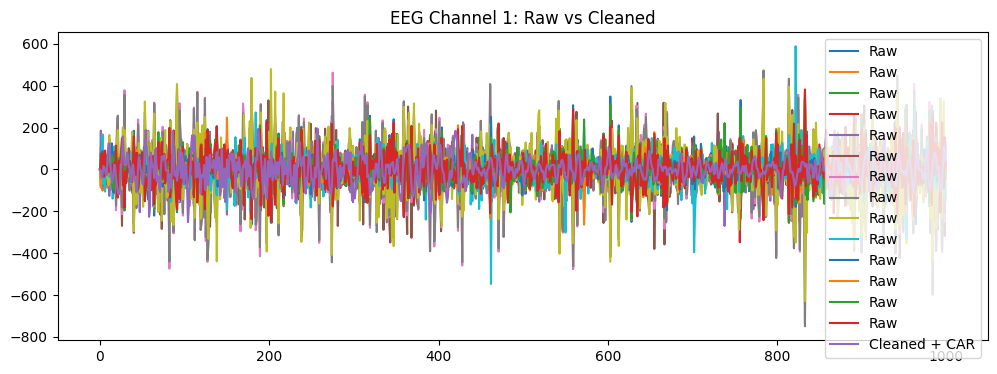

In [33]:
plt.figure(figsize=(12, 4))
plt.plot(eeg_data[:1000, 0], label='Raw')
plt.plot(car[:1000, 0], label='Cleaned + CAR')
plt.legend()
plt.title('EEG Channel 1: Raw vs Cleaned')
plt.show()


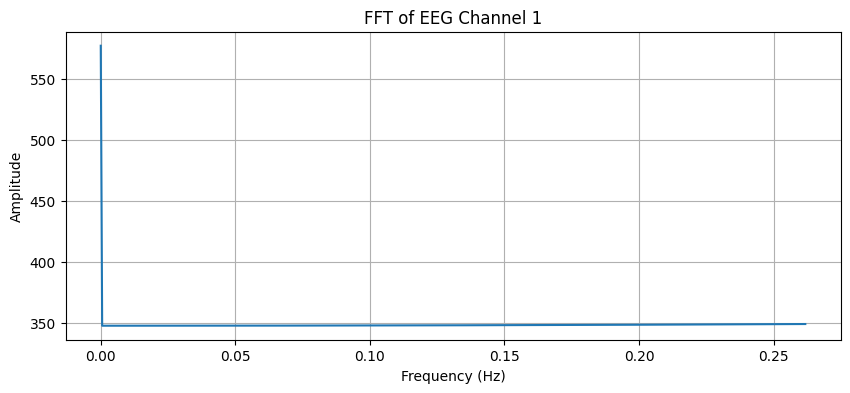

In [34]:
plt.figure(figsize=(10, 4))
plt.plot(freqs[:500], np.abs(fft_result[:500, 0]))
plt.title("FFT of EEG Channel 1")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.show()


In [35]:
import mne
n_channels = 59

# Initialize an info structure
info = mne.create_info(
        ch_names = chan_names,
        ch_types = ['eeg']*nchannels,
        sfreq    = sfreq )

print('Event created :', info)

Event created : <Info | 7 non-empty values
 bads: []
 ch_names: AF3, AF4, F5, F3, F1, Fz, F2, F4, F6, FC5, FC3, FC1, FCz, FC2, ...
 chs: 59 EEG
 custom_ref_applied: False
 highpass: 0.0 Hz
 lowpass: 50.0 Hz
 meas_date: unspecified
 nchan: 59
 projs: []
 sfreq: 100.0 Hz
>


In [36]:
# digitized electrode positions
xpos = mat['nfo']['xpos'][0][0]
ypos = mat['nfo']['ypos'][0][0]

In [37]:
layout_pos = np.concatenate([xpos, ypos], axis = 1)
layout_pos

array([[-0.20109028,  0.68656518],
       [ 0.20109028,  0.68656518],
       [-0.48547489,  0.52547424],
       [-0.32894737,  0.46520183],
       [-0.16535231,  0.43208641],
       [ 0.        ,  0.421549  ],
       [ 0.16535231,  0.43208641],
       [ 0.32894737,  0.46520183],
       [ 0.48547489,  0.52547424],
       [-0.60591541,  0.27165704],
       [-0.39919579,  0.23384348],
       [-0.19765935,  0.21394494],
       [ 0.        ,  0.20773757],
       [ 0.19765935,  0.21394494],
       [ 0.39919579,  0.23384348],
       [ 0.60591541,  0.27165704],
       [-0.74834683,  0.15177169],
       [-0.52472976,  0.12553103],
       [-0.30963911,  0.11086096],
       [-0.10226303,  0.10426648],
       [ 0.10226303,  0.10426648],
       [ 0.30963911,  0.11086096],
       [ 0.52472976,  0.12553103],
       [ 0.74834683,  0.15177169],
       [-0.87719298,  0.        ],
       [-0.64569058,  0.        ],
       [-0.421549  ,  0.        ],
       [-0.20773757,  0.        ],
       [ 0.        ,

In [38]:
layout = mne.channels.generate_2d_layout(
    xy = layout_pos,
    ch_names=chan_names,
    name ='EEG custom layout',
    )

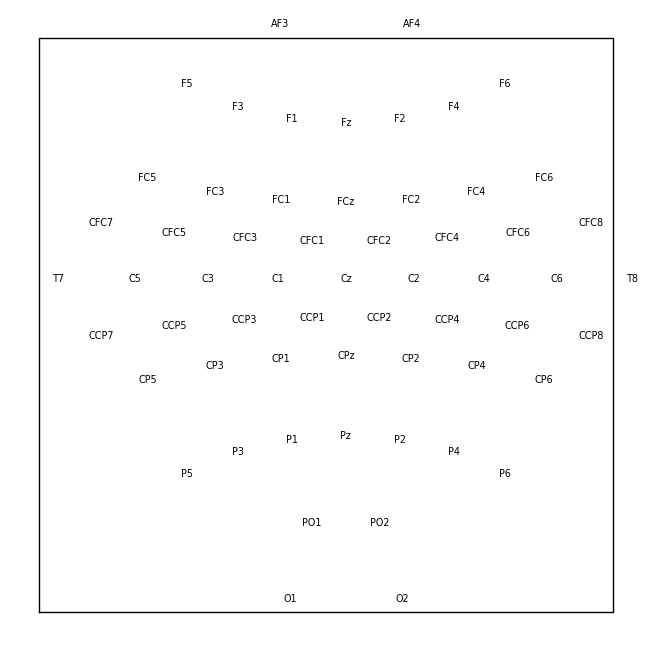

In [39]:
layout.plot();

In [40]:
# Dictionary to store the trials for each class
trials = {}

# Time window to extract for each trial: from 0.5s to 2.5s after onset
win = np.arange(int(0.5 * sfreq), int(2.5 * sfreq))  # window = 2 seconds
nsamples_window = len(win)

# Loop over each class label and its corresponding code
for cl, code in zip(cl_lab, np.unique(event_codes)):

    # Get all onset indices for the current class
    cl_onsets = event_onsets[event_codes == code]

    # Filter out onsets that would cause indexing beyond the data length
    valid_onsets = [onset for onset in cl_onsets if onset + win[-1] < EEGdata.shape[1]]

    # Allocate memory: shape (channels, time, trials)
    trials[cl] = np.zeros((nchannels, nsamples_window, len(valid_onsets)))

    # Extract trials
    for i, onset in enumerate(valid_onsets):
        trials[cl][:, :, i] = EEGdata[:, win + onset]

# Print shapes to verify
print('Shape of trials[{}]:'.format(cl1), trials[cl1].shape)
print('Shape of trials[{}]:'.format(cl2), trials[cl2].shape)


Shape of trials[left]: (59, 200, 100)
Shape of trials[right]: (59, 200, 100)


In [41]:
selected_channels = ['Fp1', 'Fp2', 'C3', 'C4', 'P7', 'P8', 'O1', 'O2']
freq_bands = {
    'delta': (0.5, 4),
    'theta': (4, 8),
    'alpha': (8, 13),
    'beta': (13, 30)
}


In [42]:
from scipy.signal import butter, lfilter

def bandpass_filter(data, lowcut, highcut, fs, order=5):
    nyquist = 0.5 * fs
    low = lowcut / nyquist
    high = highcut / nyquist
    b, a = butter(order, [low, high], btype='band')
    return lfilter(b, a, data)


In [46]:
import numpy as np
import pandas as pd

all_features = []
all_labels = []

for cl in cl_lab:
    trial_data = trials[cl]  # shape: (channels, time, trials)

    for i in range(trial_data.shape[2]):
        trial = trial_data[:, :, i]
        features = []

        for ch_name in selected_channels:
            ch_idx = selected_channels.index(ch_name)  # Get index of channel by name
            ch_signal = trial[ch_idx, :]

            for band_name, (low_f, high_f) in freq_bands.items():
                band_sig = bandpass_filter(ch_signal, low_f, high_f, sfreq)
                features.append(np.std(band_sig))
                features.append(np.mean(band_sig))

        all_features.append(features)
        all_labels.append(cl)


In [47]:
columns = []
for ch in selected_channels:
    for band in freq_bands:
        columns += [f'{ch} {band} std', f'{ch} {band} m']

df_features = pd.DataFrame(all_features, columns=columns)
df_features.insert(0, 'Class', all_labels)
df_features.head()


,Class,Fp1 delta std,Fp1 delta m,Fp1 theta std,Fp1 theta m,Fp1 alpha std,Fp1 alpha m,Fp1 beta std,Fp1 beta m,Fp2 delta std,...,O1 beta std,O1 beta m,O2 delta std,O2 delta m,O2 theta std,O2 theta m,O2 alpha std,O2 alpha m,O2 beta std,O2 beta m
0,left,244.752057,0.211437,91.410501,0.153011,61.254789,0.181089,65.473097,-0.317532,172.009155,...,47.550023,-0.303864,62.816486,-2.795627,45.575323,0.183810,34.679068,0.226656,45.691874,-0.344214
1,left,407.104328,28.171866,130.536121,-0.505372,77.809902,-0.069744,75.857796,-0.223760,256.540405,...,38.642045,-0.119794,107.393721,12.697571,41.848860,-0.453297,31.929168,0.058642,28.819614,-0.160133
2,left,275.934295,14.413043,94.888396,-1.043181,46.300667,-0.290868,62.207438,-0.276251,156.246430,...,48.577109,-0.169440,154.658008,13.836343,49.209503,-0.676609,34.310560,0.274090,49.780061,-0.170018
3,left,195.185837,10.209966,60.078680,-0.452583,57.917730,-0.712108,42.639116,-0.260224,158.643864,...,35.438603,-0.304035,230.715868,11.346676,72.078138,-0.297480,64.975239,-0.122745,53.553567,-0.251892
4,left,187.634440,8.917196,60.582987,-0.469274,54.587040,0.203841,43.698465,-0.035154,127.788225,...,36.693552,0.063941,139.983565,5.448474,48.672110,-0.623910,62.928463,0.511019,41.869190,0.111811


In [48]:
# Save features to CSV
csv_path = 'eeg_features.csv'
df_features.to_csv(csv_path, index=False)

print(f"Features saved to: {csv_path}")


Features saved to: eeg_features.csv


In [58]:
left_hand  = np.rollaxis(trials[cl1], 2, 0)
right_hand = np.rollaxis(trials[cl2], 2, 0)

In [59]:
left_hand.shape

(100, 59, 200)

In [60]:
data = np.concatenate([left_hand, right_hand])

In [61]:
# create labels
Y = np.concatenate([-np.ones(left_hand.shape[0]),
                     np.ones(right_hand.shape[0])])

In [62]:
# Create an event matrix: events with alternating event codes
eventLength = Y.shape[0]
ev = [i*sfreq*3 for i in range(eventLength)]

events = np.column_stack((np.array(ev,  dtype = int),
                          np.zeros(eventLength,  dtype = int),
                          np.array(Y,  dtype = int)))

<ipython-input-62-f19e8c3cd27d>:3: RuntimeWarning: overflow encountered in scalar multiply
  ev = [i*sfreq*3 for i in range(eventLength)]


In [63]:
events

array([[  0,   0,  -1],
       [ 44,   0,  -1],
       [ 88,   0,  -1],
       [132,   0,  -1],
       [176,   0,  -1],
       [220,   0,  -1],
       [  8,   0,  -1],
       [ 52,   0,  -1],
       [ 96,   0,  -1],
       [140,   0,  -1],
       [184,   0,  -1],
       [228,   0,  -1],
       [ 16,   0,  -1],
       [ 60,   0,  -1],
       [104,   0,  -1],
       [148,   0,  -1],
       [192,   0,  -1],
       [236,   0,  -1],
       [ 24,   0,  -1],
       [ 68,   0,  -1],
       [112,   0,  -1],
       [156,   0,  -1],
       [200,   0,  -1],
       [244,   0,  -1],
       [ 32,   0,  -1],
       [ 76,   0,  -1],
       [120,   0,  -1],
       [164,   0,  -1],
       [208,   0,  -1],
       [252,   0,  -1],
       [ 40,   0,  -1],
       [ 84,   0,  -1],
       [128,   0,  -1],
       [172,   0,  -1],
       [216,   0,  -1],
       [  4,   0,  -1],
       [ 48,   0,  -1],
       [ 92,   0,  -1],
       [136,   0,  -1],
       [180,   0,  -1],
       [224,   0,  -1],
       [ 12,   0

In [64]:
print("event_id:", event_id)


event_id: {'left': -1, 'right': 1}


In [65]:
print(f"Data shape: {data.shape}")  # Should be (n_epochs, n_channels, n_times)
print(f"Events shape: {events.shape}")  # Should be (n_events, 3)

Data shape: (200, 59, 200)
Events shape: (200, 3)


In [75]:
print(f"Number of epochs in data: {data.shape[0]}")
print(f"Number of events: {events.shape[0]}")

Number of epochs in data: 200
Number of events: 200


In [2]:
# Dictionary to store the trials for each class
trials = {}
